In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_csv('ENFR 2018 - Base usuario.txt', sep='|')

## Contexto dataset

### Encuesta Nacional de Factores de Riesgo (ENFR) 2018

El objetivo de esta encuesta, realizada por el INDEC, es estudiar los comportamientos y condiciones de vida que pueden afectar la salud de la población de 18 años y más, así como algunas características de las viviendas y de los hogares donde residen.

## Analisis de columnas

In [7]:
df.columns

Index(['id', 'cod_provincia', 'region', 'tamanio_aglomerado', 'aglomerado',
       'localidades_150', 'submuestra', 'bhcv01', 'bhcv02', 'bhcv03',
       ...
       'glucemia_elevada', 'prevalencia_glucemia_elevada_combinada',
       'findrisc', 'bimq06', 'bimq06_01', 'colesterol_elevado',
       'prevalencia_colesterol_combinada', 'wf1p', 'wf2p', 'wf3p'],
      dtype='str', length=287)

In [12]:
df[["bhcv03"]].value_counts()

bhcv03
1         25088
2          3860
3           208
4            68
Name: count, dtype: int64

#### Link donde se explica a detalle cada columna con su valor asociado: https://www.indec.gob.ar/ftp/cuadros/menusuperior/enfr/manual_base_usuario_enfr2018.pdf

- **id, cod_provincia, region, tamanio_aglomerado, aglomerado:** Identifican dónde vive la persona

- **bhcv01–bhcv11:** Bloque de características de la vivienda.

- **bhho01–bhho03:** Características del hogar.

- **cant_componentes, miembros_18, tipo_hogar:** Composición del hogar.

- **bhih01, rango_ingreso, quintil_uc:** Ingresos y nivel económico del hogar.

- **bhch...:** Datos sociodemográficos, como edad, educación y cobertura de salud.

- **bisl..., bisg...:** Variables de salud y otros aspectos sociodemográficos.

- **biaf...:** Actividad física y sus barreras.

- **bita...:** Tabaco y aspectos relacionados con su consumo.

- **biha...:** Hipertensión arterial.

- **bipc..., imc, imc_categorias:** Peso, talla e índice de masa corporal.

- **bial...:** Alimentación y consumo de frutas y verduras.

- **bico...:**  Colesterol.

- **bica..., consumo_regular_riesgo:** Consumo de alcohol y patrones de riesgo.

- **bidi...:** Diabetes.

- **bile..., bipp..., bicc...:** Otros controles de salud, prevención y detección de enfermedades.

- **bima..., bimq...:** Mediciones físicas y bioquímicas de la submuestra.

- **wf1p, wf2p, wf3p:** Variables de ponderación o factores de expansión; hay que consultar el diccionario para distinguirlas.

In [13]:
df["wf1p"].value_counts()

wf1p
189     58
150     57
227     56
126     55
154     55
        ..
1832     1
2184     1
26       1
2088     1
1414     1
Name: count, Length: 4175, dtype: int64

In [5]:
df.head()

,id,cod_provincia,region,tamanio_aglomerado,aglomerado,localidades_150,submuestra,bhcv01,bhcv02,bhcv03,...,glucemia_elevada,prevalencia_glucemia_elevada_combinada,findrisc,bimq06,bimq06_01,colesterol_elevado,prevalencia_colesterol_combinada,wf1p,wf2p,wf3p
0,1128639,2,1,1,1,1,1,3,2,1,...,NaN,NaN,2.0,NaN,NaN,NaN,NaN,2378,4464,0
1,1709939,2,1,1,1,1,0,1,4,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3588,0,0
2,6874130,2,1,1,1,1,0,3,2,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2740,0,0
3,10319375,2,1,1,1,1,1,3,1,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,493,0,0
4,11140857,2,1,1,1,1,0,3,3,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2016,0,0


## Nulos

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 29224 entries, 0 to 29223
Columns: 287 entries, id to wf3p
dtypes: float64(186), int64(101)
memory usage: 64.0 MB


### El dataset tiene 29.224 registros con 287 columnas

In [7]:
porcentaje_nulos = (df.isnull().sum() / len(df)) * 100

columnas_con_nulos = porcentaje_nulos[porcentaje_nulos > 0].sort_values(ascending=False)

df_nulos = pd.DataFrame({'Porcentaje de Nulos (%)': columnas_con_nulos})

df_nulos.head(32)

,Porcentaje de Nulos (%)
bita06_b_99,99.941829
biha06_99,99.921298
biaf02_99,99.869970
biha11_99,99.842595
biaf04_99,99.811799
bita02_99,99.562004
bimq05_01,99.510676
bica03_99,99.473036
bhch10_99,99.473036
bhch10_99_j,99.469614


#### Hay columnas con muchos nulos, podemos ver que hay 17 columnas con mas del 99% de nulos

## Variables de interes

bhch04
18     439
19     433
20     505
21     499
22     535
      ... 
95      13
96       3
97       4
99       2
104      1
Name: count, Length: 82, dtype: int64


<Axes: title={'center': 'Distribución de bhch04'}, xlabel='bhch04'>

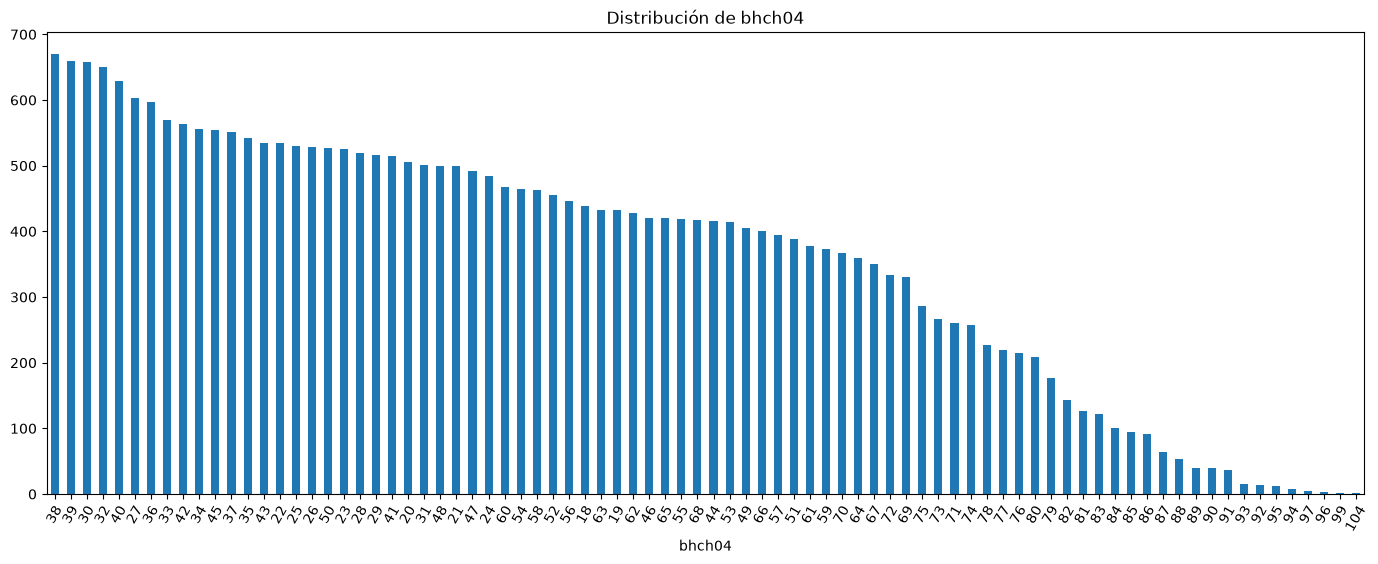

In [58]:
# edad (bhch04)
# Como la edad va desde 18 hasta 104 como dice en la documentación, vamos a ver la distribución de la edad para ver si hay algún valor que no corresponda a este rango.
print(df["bhch04"].value_counts().sort_index())
df["bhch04"].value_counts().plot(kind='bar', figsize=(17, 6), xlabel='bhch04', rot=60, y='count', title='Distribución de bhch04')

imc
10.38    1
13.73    1
13.84    2
14.27    1
14.33    1
        ..
62.50    1
63.72    1
65.74    1
66.60    1
66.67    1
Name: count, Length: 1913, dtype: int64


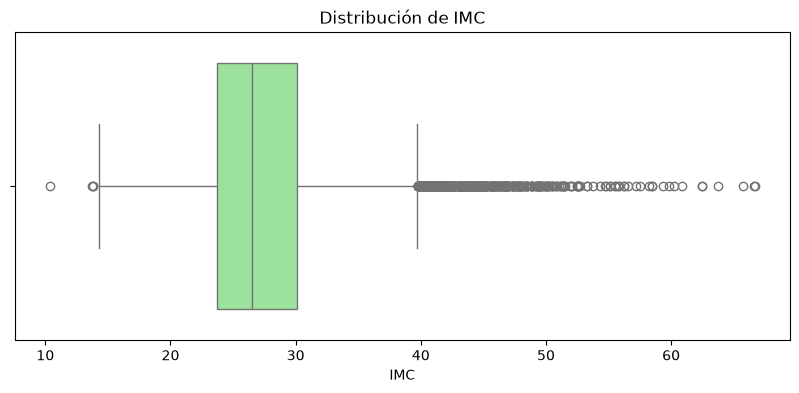

In [ ]:
# indice masa corporal (imc)
# 10.38 es un valor atipico por ser muy bajo y tenemos muchos valores atipicos por ser muy altos, pero ningun dato parece ser incorrecto
print(df["imc"].value_counts().sort_index())

plt.figure(figsize=(10, 4))
sns.boxplot(x=df["imc"], color="lightgreen")
plt.title("Distribución de IMC")
plt.xlabel("IMC")
plt.show()

<Axes: title={'center': 'Nivel de actividad física (1=Alto, 2=Media, 3=Bajo, 4=Ns/Nc'}, xlabel='nivel_actividad_fisica'>

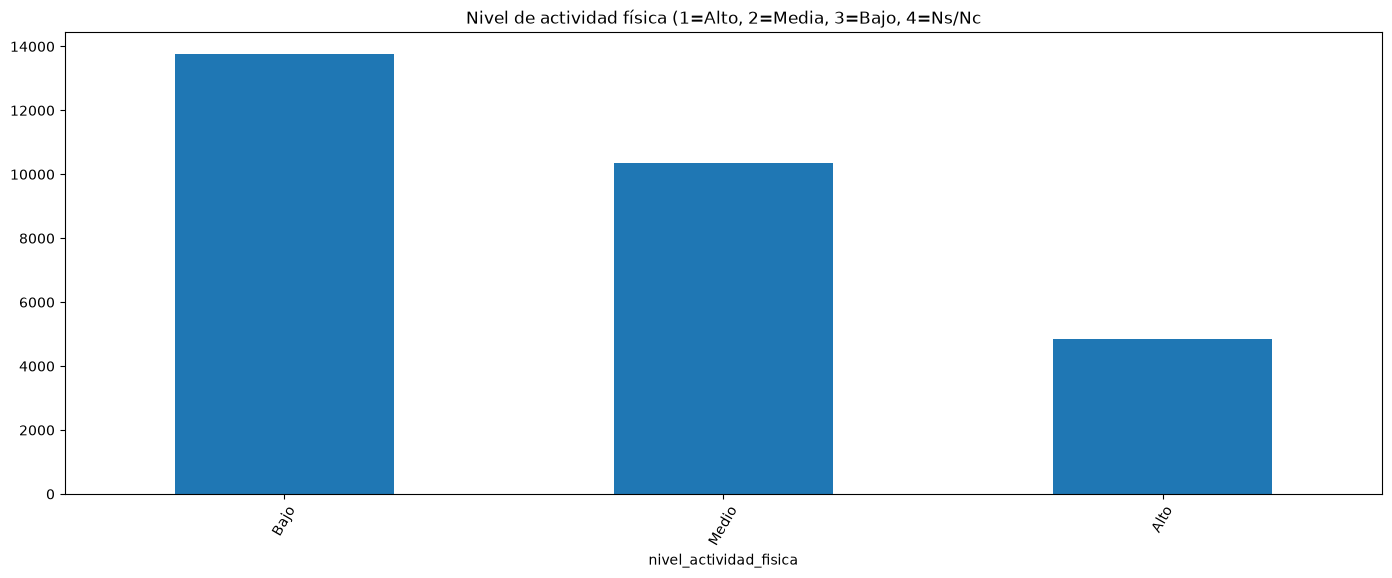

In [ ]:
# Nivel actividad fisica (nivel_actividad_fisica)

etiquetas = {
    1: 'Alto', 
    2: 'Medio', 
    3: 'Bajo', 
    4: 'Ns/Nc'
}
df["nivel_actividad_fisica"].replace(etiquetas).value_counts().plot(kind='bar', figsize=(17, 6), xlabel='nivel_actividad_fisica', rot=60, y='count', title='Nivel de actividad física (1=Alto, 2=Media, 3=Bajo, 4=Ns/Nc')

<Axes: title={'center': 'Condicion fumador (1=fumador, 2=exfumador, 3=nunca fumó)'}, xlabel='consumo_tabaco_100'>

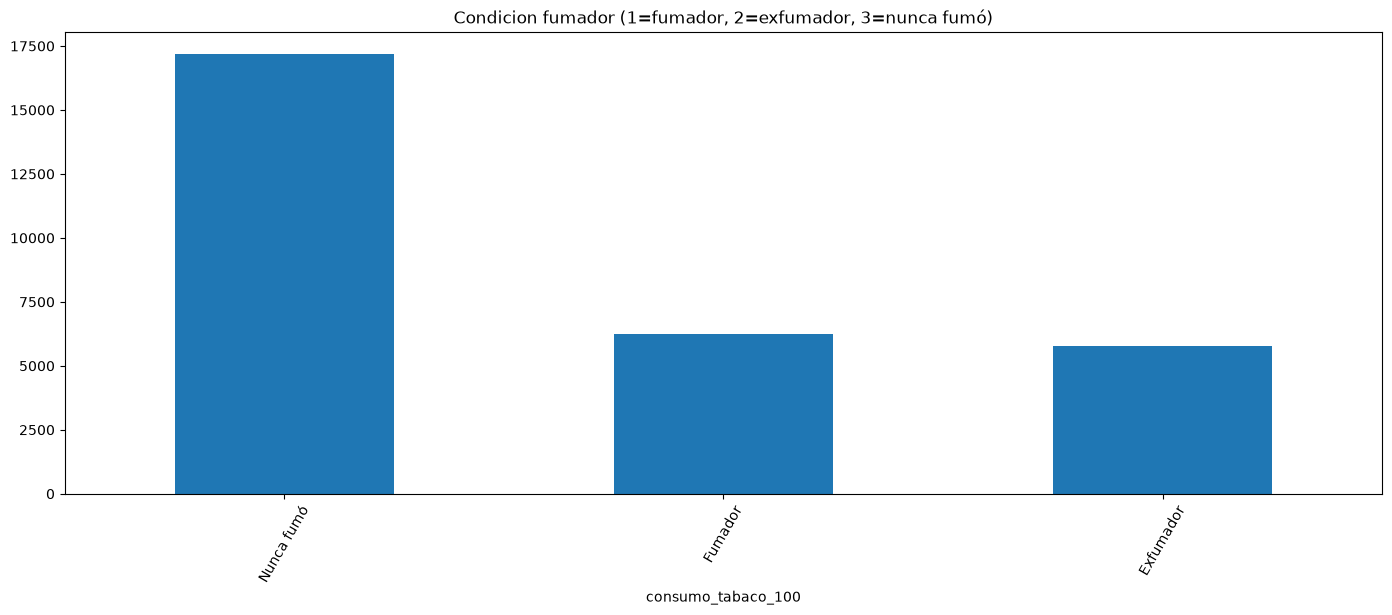

In [59]:
# condicion fumador (consumo_tabaco_100)

# Hay casi la misma cantidad de fumadores y exfumadores, y muchas personas nunca fumaron. Esto es interesante porque nos permite ver que hay una gran cantidad de personas que han dejado de fumar, lo cual es positivo para la salud pública.

etiquetas = {
    1: 'Fumador', 
    2: 'Exfumador', 
    3: 'Nunca fumó'
}
df["consumo_tabaco_100"].replace(etiquetas).value_counts().plot(kind='bar', figsize=(17, 6), xlabel='consumo_tabaco_100', rot=60, y='count', title='Condicion fumador (1=fumador, 2=exfumador, 3=nunca fumó)')

<Axes: title={'center': 'Nivel educativo alcanzado (1=Hasta primario incompleto, 2=Hasta secundario incompleto, 3=Secundario completo y mas)'}, xlabel='nivel_instruccion_agrupado'>

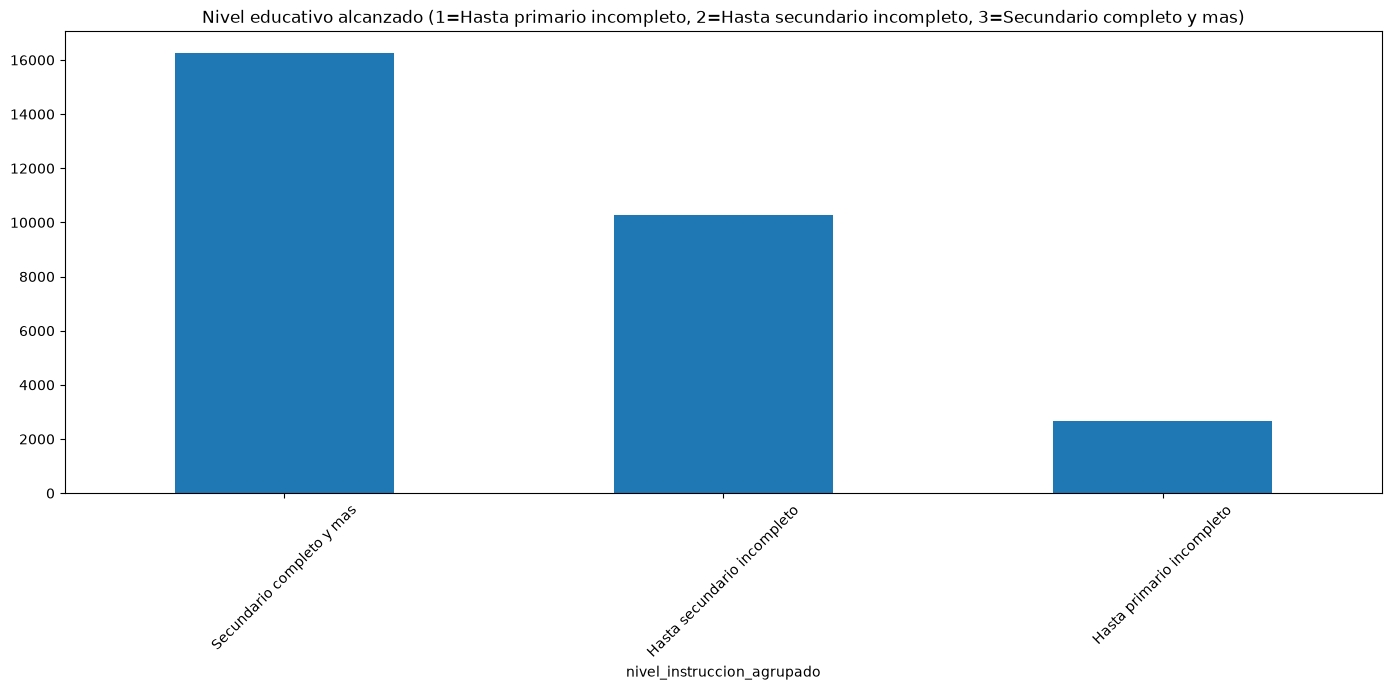

In [ ]:
# edad (nivel_instruccion_agrupado)

# Podemos ver que hay muy pocas personas que no terminaron la primearia, pero tambien hay muchas que no terminaron la secundaria. En el futuro vamos a analizar las edades de las personas que no terminaron la secundaria para ver si hay alguna relación entre la edad y el nivel educativo alcanzado.

etiquetas = {
    1: 'Hasta primario incompleto',
    2: 'Hasta secundario incompleto',
    3: 'Secundario completo y mas'
}

df["nivel_instruccion_agrupado"].replace(etiquetas).value_counts().plot(kind='bar', figsize=(17, 6), rot=45, y='count', title='Nivel educativo alcanzado (1=Hasta primario incompleto, 2=Hasta secundario incompleto, 3=Secundario completo y mas)')